# TweetEval – Offensive Language Detection
## Notebook 01 · Exploratory Data Analysis (EDA)

| | |
|---|---|
| **Course** | Machine Learning – CI1 – Faculté des Sciences de Bizerte |
| **Group members** | *Member 1 · Member 2 · Member 3 · Member 4* ← **fill in** |
| **Dataset chosen** | TweetEval – Offensive (binary: `offensive` / `non-offensive`) |
| **Task** | Predict whether a tweet is offensive |

---

### Goal of this notebook
Before training any model we must **understand the data**: its structure, its quality, the balance between the classes,
the length and style of the tweets, and the vocabulary that separates offensive from non-offensive tweets.
Every observation made here is translated into a **decision for the preprocessing** (notebook 02) and for the choice of
evaluation metrics.

### Contents
1. [Setup](#1)
2. [Loading the data](#2)
3. [Structure of the data](#3)
4. [Data quality checks](#4)
5. [Class distribution](#5)
6. [Text length analysis](#6)
7. [Stylistic / surface features](#7)
8. [Vocabulary analysis](#8)
9. [WordClouds per class](#9)
10. [Example tweets](#10)
11. [Conclusions & implications for preprocessing](#11)
12. [Saving the results](#12)

> **How to read this notebook.** Code cells are commented line by line. Every cell that produces a result is followed by a
> **Results explained** cell that says what the output shows, how to read it, and what it implies for the rest of the project.
> All output folders (`results/figures/01_data_exploration/` and `results/metrics/01_data_exploration/`) are **created
> automatically** by the setup cell.

<a id="1"></a>
## 1. Setup
Imports, paths, automatic creation of the output folders, and a consistent colour scheme (blue = non-offensive, red = offensive).

In [1]:
import re, sys, warnings                 # re: regular expressions | sys: import path | warnings: hide noise
from pathlib import Path                 # OS-independent file paths
from collections import Counter          # fast word counting

import numpy as np                       # numerical computing
import pandas as pd                      # tables (DataFrames)
import matplotlib.pyplot as plt          # plotting
import seaborn as sns                    # statistical plots and nicer styles
from scipy.stats import mannwhitneyu     # non-parametric test used to compare tweet lengths
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS   # standard English stop-word list
from wordcloud import WordCloud          # word-cloud images

warnings.filterwarnings("ignore")                       # keep the output readable
sns.set_theme(style="whitegrid", context="notebook")    # consistent plot style
plt.rcParams["figure.dpi"] = 110                        # sharper figures on screen

# --- Project root: works whether the notebook is launched from the root or from notebooks/ ---
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))                   # so that `import src...` works

# --- Folders ------------------------------------------------------------------
RAW_DIR = PROJECT_ROOT / "data" / "raw"                 # raw official files (never edited)
FIG_DIR = PROJECT_ROOT / "results" / "figures"
MET_DIR = PROJECT_ROOT / "results" / "metrics"

# Sub-folders dedicated to THIS notebook (one sub-folder per notebook keeps results organised)
NB_NAME = "01_data_exploration"
EDA_FIG_DIR = FIG_DIR / NB_NAME
EDA_MET_DIR = MET_DIR / NB_NAME

# Create every folder automatically.
# parents=True -> also creates missing parent folders | exist_ok=True -> no error if the folder already exists
for d in (RAW_DIR, FIG_DIR, MET_DIR, EDA_FIG_DIR, EDA_MET_DIR):
    d.mkdir(parents=True, exist_ok=True)

# --- Labels and colours (used by every plot) ----------------------------------
LABEL_NAMES = {0: "non-offensive", 1: "offensive"}
COLORS = {"non-offensive": "#4C78A8", "offensive": "#E45756"}     # blue / red
PALETTE = [COLORS["non-offensive"], COLORS["offensive"]]

def savefig(fig, name):
    """Save a figure into results/figures/01_data_exploration/, display it, then close it.
    The figure is passed explicitly, so we can never save the wrong one by mistake."""
    fig.tight_layout()                                          # avoid overlapping labels
    fig.savefig(EDA_FIG_DIR / name, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)                                              # free memory

print("Project root   :", PROJECT_ROOT)
print("Raw data dir   :", RAW_DIR)
print("Figures saved in:", EDA_FIG_DIR)
print("Metrics saved in:", EDA_MET_DIR)

Project root   : c:\Users\ASUS\Desktop\TweetEval-offensiveML
Raw data dir   : c:\Users\ASUS\Desktop\TweetEval-offensiveML\data\raw
Figures saved in: c:\Users\ASUS\Desktop\TweetEval-offensiveML\results\figures\01_data_exploration
Metrics saved in: c:\Users\ASUS\Desktop\TweetEval-offensiveML\results\metrics\01_data_exploration


**Results explained.**
- The printed paths confirm that the notebook found the project root and will read the raw files from `data/raw/`. If the notebook is launched from `notebooks/`, the root is the parent folder; on another machine the paths differ, which is harmless.
- The two output sub-folders now exist (they are created by the `mkdir` loop), so no later `savefig` or `to_csv` can fail because of a missing folder.
- Nothing statistical here: the cell fixes the conventions used everywhere below (seaborn style, the `savefig` helper, **blue = non-offensive, red = offensive**).

<a id="2"></a>
## 2. Loading the data

The official TweetEval repository provides **six plain-text files** (one tweet / one label per line):

| Split | Files | Role in the project |
|---|---|---|
| train | `train_text.txt`, `train_labels.txt` | fit the vectorizer and the models |
| val | `val_text.txt`, `val_labels.txt` | model selection |
| test | `test_text.txt`, `test_labels.txt` | final evaluation **only** |

The cell below downloads the files into `data/raw/` if they are missing (raw files are never edited afterwards),
then loads them using `src/data_loader.py` (with an identical fallback if the module is not found).

In [2]:
import urllib.request

# Official location of the dataset
BASE_URL = "https://raw.githubusercontent.com/cardiffnlp/tweeteval/main/datasets/offensive/"
# Build the six file names: train_text.txt, train_labels.txt, val_text.txt, ...
FILES = [f"{s}_{k}.txt" for s in ("train", "val", "test") for k in ("text", "labels")]

for fname in FILES:
    target = RAW_DIR / fname
    if not target.exists():                          # download only what is missing
        print("Downloading", fname)
        urllib.request.urlretrieve(BASE_URL + fname, target)

# Preferred: the project loader. Fallback: an identical function defined here.
try:
    from src.data_loader import load_all
except ImportError:
    def _read_lines(path):
        with open(path, encoding="utf-8") as f:
            return [line.rstrip("\n") for line in f]          # one tweet / label per line

    def load_all(raw_dir=RAW_DIR):
        out = []
        for s in ("train", "val", "test"):
            texts = _read_lines(Path(raw_dir) / f"{s}_text.txt")
            labels = [int(x) for x in _read_lines(Path(raw_dir) / f"{s}_labels.txt")]
            assert len(texts) == len(labels), f"{s}: texts/labels mismatch"   # alignment check
            out.append(pd.DataFrame({"text": texts, "label": labels}))
        return tuple(out)

train_df, val_df, test_df = load_all()

# One big table with a "split" column: convenient for grouped statistics and plots
full_df = pd.concat(
    [train_df.assign(split="train"), val_df.assign(split="val"), test_df.assign(split="test")],
    ignore_index=True,
)
full_df["label_name"] = full_df["label"].map(LABEL_NAMES)                              # 0/1 -> readable name
full_df["split"] = pd.Categorical(full_df["split"], ["train", "val", "test"], ordered=True)   # fixed display order

print(f"train: {len(train_df):>6} tweets")
print(f"val  : {len(val_df):>6} tweets")
print(f"test : {len(test_df):>6} tweets")
print(f"total: {len(full_df):>6} tweets")

train:  11916 tweets
val  :   1324 tweets
test :    860 tweets
total:  14100 tweets


**Results explained.**
- The official splits contain **11,916 / 1,324 / 860 tweets** (14,100 in total), i.e. about 84.5 % / 9.4 % / 6.1 %. If no `Downloading ...` line was printed, the six raw files were already present locally.
- The **test set is small**: one tweet is worth about 0.12 accuracy points, so test scores will be noisier than validation scores.
- The loader checks `len(texts) == len(labels)` for every split, so the absence of an assertion error means texts and labels are aligned line by line.

<a id="3"></a>
## 3. Structure of the data
`.head()`, `.info()` and `.describe()` as requested in the assignment.

In [3]:
print("=== HEAD (train) ===")
display(train_df.head(10))       # first 10 tweets with their label

=== HEAD (train) ===


,text,label
0,@user Bono... who cares. Soon people will unde...,0
1,@user Eight years the republicans denied obama...,1
2,@user Get him some line help. He is gonna be j...,0
3,@user @user She is great. Hi Fiona!,0
4,@user She has become a parody unto herself? Sh...,1
5,@user @user @user @user @user @user @user @use...,0
6,@user Your looking more like a plant #maga #wa...,1
7,@user @user Lol. Except he’s the most successf...,0
8,@user Been a Willie fan since before most of y...,0
9,@user Here's a link to my channel with a pleth...,0


**Results explained.**
- The data has exactly two columns: `text` (the tweet) and `label` (0 = non-offensive, 1 = offensive).
- All 10 tweets shown start with `@user`: most of the corpus consists of **replies**, and mentions were anonymised by the dataset authors. Row 5 is an extreme case: a long chain of `@user`.
- 3 of the 10 tweets are offensive (rows 1, 4, 6), close to the global rate of 33 %.
- Offensive does not mean profane. Row 1 ("...as phony as their fake president") and row 6 ("looking more like a plant") contain no swear word; only row 4 has an explicit insult (`idiot`). A first hint that vocabulary alone will not explain every label.

In [4]:
# .info(): number of rows, column types, non-null counts (-> missing values), memory usage
print("=== INFO (train) ===")
train_df.info()
print("\n=== INFO (val) ===")
val_df.info()
print("\n=== INFO (test) ===")
test_df.info()

=== INFO (train) ===
<class 'pandas.DataFrame'>
RangeIndex: 11916 entries, 0 to 11915
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    11916 non-null  str  
 1   label   11916 non-null  int64
dtypes: int64(1), str(1)
memory usage: 186.3 KB

=== INFO (val) ===
<class 'pandas.DataFrame'>
RangeIndex: 1324 entries, 0 to 1323
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    1324 non-null   str  
 1   label   1324 non-null   int64
dtypes: int64(1), str(1)
memory usage: 20.8 KB

=== INFO (test) ===
<class 'pandas.DataFrame'>
RangeIndex: 860 entries, 0 to 859
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    860 non-null    str  
 1   label   860 non-null    int64
dtypes: int64(1), str(1)
memory usage: 13.6 KB


**Results explained.**
- All three splits have **0 missing values** in both columns (non-null count = number of rows), so no imputation is required.
- Types are as expected: `text` is a string column and `label` is an integer.
- The whole dataset is tiny (about 186 KB for train, 21 KB for val, 14 KB for test): everything fits in memory and every experiment runs quickly.

In [5]:
# .describe(include="all"): statistics for ALL columns (count/unique/top/freq for text, mean/std/quartiles for label)
print("=== DESCRIBE – all columns (train) ===")
display(train_df.describe(include="all"))

# Check that only the values 0 and 1 occur in the label column of every split
print("Unique label values per split:")
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"  {name:5s} -> {sorted(d['label'].unique())}")

=== DESCRIBE – all columns (train) ===


,text,label
count,11916,11916.000000
unique,11883,NaN
top,@user Looks Like The Jokes On Liberals Again. ...,NaN
freq,5,NaN
mean,NaN,0.330732
std,NaN,0.470496
min,NaN,0.000000
25%,NaN,0.000000
50%,NaN,0.000000
75%,NaN,1.000000


Unique label values per split:
  train -> [np.int64(0), np.int64(1)]
  val   -> [np.int64(0), np.int64(1)]
  test  -> [np.int64(0), np.int64(1)]


**Results explained.**
- `unique = 11,883` out of `count = 11,916` means **33 duplicated tweets** in train, which matches the quality table in section 4. The most repeated tweet appears 5 times.
- `label` mean = **0.3307**: 33.07 % of train tweets are offensive. The median is 0 and the 75th percentile is 1, which only says that class 0 is the majority.
- The standard deviation (0.4705) is exactly the value expected for a yes/no variable with p = 0.33 (sqrt(p(1-p))), so it carries no extra information.
- Only the values 0 and 1 occur in each split: no corrupted label.

**Reading guide.** The dataset has only two columns: `text` (a string) and `label`. Since there are no numerical features, `describe()` is only informative for `label`: its mean is the proportion of offensive tweets. Richer numerical descriptors (length, punctuation, …) are built in sections 6 and 7.

<a id="4"></a>
## 4. Data quality checks
Before modelling we verify: missing values, empty texts, duplicates, and — most importantly — **overlap between splits**
(identical tweets in train and test would inflate the final score = data leakage).

In [6]:
quality = []
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    quality.append({
        "split": name,
        "n_rows": len(d),
        "missing_text": d["text"].isna().sum(),                    # NaN texts
        "missing_label": d["label"].isna().sum(),                  # NaN labels
        "empty_text": (d["text"].str.strip() == "").sum(),         # blank tweets
        "duplicate_texts": d["text"].duplicated().sum(),           # 2nd and later copies of a text
        "duplicate_%": round(100 * d["text"].duplicated().mean(), 2),
    })
quality_df = pd.DataFrame(quality).set_index("split")
display(quality_df)

,n_rows,missing_text,missing_label,empty_text,duplicate_texts,duplicate_%
split,,,,,,
train,11916,0,0,0,33,0.28
val,1324,0,0,0,1,0.08
test,860,0,0,0,11,1.28


**Results explained.**
- No missing text, no missing label and no empty text in any split.
- Duplicated texts: **33 in train (0.28 %), 1 in val (0.08 %), 11 in test (1.28 %)**. The test set has the highest rate, but in absolute terms it is only 11 tweets.
- The counts include only the second and later copies of a text (`duplicated()`), so the first occurrence is not counted.
- Conclusion: the data is structurally clean; no row needs to be dropped.

In [7]:
# Overlap between splits: intersection of the sets of texts (data leakage check)
tr, va, te = set(train_df["text"]), set(val_df["text"]), set(test_df["text"])
print("Identical tweets  train ∩ val :", len(tr & va))
print("Identical tweets  train ∩ test:", len(tr & te))
print("Identical tweets  val   ∩ test:", len(va & te))

# Label noise: the same text carrying both labels inside train
grp = train_df.groupby("text")["label"].nunique()       # number of distinct labels per text
print("\nTweets appearing with both labels in train:", int((grp > 1).sum()))

Identical tweets  train ∩ val : 4
Identical tweets  train ∩ test: 4
Identical tweets  val   ∩ test: 0

Tweets appearing with both labels in train: 6


**Results explained.**
- Overlap between splits: **4 tweets in both train and val, 4 in both train and test, 0 in both val and test**.
- The risk of leakage is negligible: 4 of 860 test tweets (0.47 %) also exist in train, so even a model that memorised them could improve test accuracy by less than half a point.
- **6 train tweets carry both labels** (6 / 11,916 = 0.05 %). This is annotation noise: the same text was judged differently, which shows that a perfect score is impossible and that the labels are partly subjective.
- Decision: leave the raw data untouched and simply mention this in the report.

<a id="5"></a>
## 5. Class distribution
Is the dataset balanced? This drives the choice of metrics: with an imbalanced dataset, **accuracy alone is misleading**
and precision / recall / F1 of the *offensive* class matter more.

In [8]:
# Count tweets per (split, class) -> wide table with one column per class
counts = (full_df.groupby(["split", "label_name"]).size().unstack(fill_value=0))[["non-offensive", "offensive"]]
counts["total"] = counts.sum(axis=1)
counts["% offensive"] = (100 * counts["offensive"] / counts["total"]).round(2)
counts["% non-offensive"] = (100 - counts["% offensive"]).round(2)
display(counts)

# Baseline: a "model" that always answers the majority class
maj = counts.loc["train", "non-offensive"] / counts.loc["train", "total"]
print(f"\nMajority-class baseline on train = {maj:.3f}  (a model that always predicts 'non-offensive')")
print(f"Imbalance ratio on train (non-off / off) = {counts.loc['train','non-offensive']/counts.loc['train','offensive']:.2f} : 1")

label_name,non-offensive,offensive,total,% offensive,% non-offensive
split,,,,,
train,7975,3941,11916,33.07,66.93
val,865,459,1324,34.67,65.33
test,620,240,860,27.91,72.09



Majority-class baseline on train = 0.669  (a model that always predicts 'non-offensive')
Imbalance ratio on train (non-off / off) = 2.02 : 1


**Results explained.**
- Offensive share: **33.07 % (train), 34.67 % (val), 27.91 % (test)**. Counts: 7,975 vs 3,941 in train, 865 vs 459 in val, 620 vs 240 in test.
- The majority-class baseline is **0.669** on train (imbalance ratio 2.02 : 1). On the test set the same trivial baseline would reach about 0.72 (620 / 860). A model must beat these numbers, and accuracy alone is not enough: **F1, precision and recall of the offensive class** are the right metrics.
- Validation (34.7 %) is close to train (33.1 %), while test is about 5 points lower: the test set follows a different class prior.

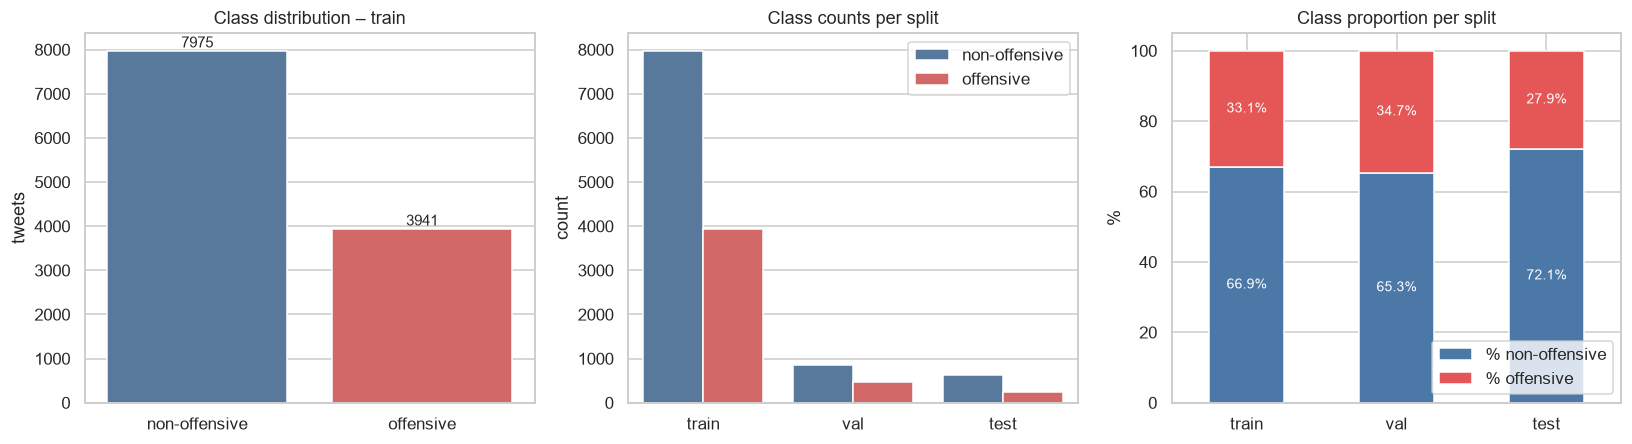

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# (a) class counts in train, with the value written above each bar
ax = axes[0]
sns.countplot(x="label_name", data=full_df[full_df.split == "train"],
              order=["non-offensive", "offensive"], palette=COLORS, ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Class distribution – train"); ax.set_xlabel(""); ax.set_ylabel("tweets")

# (b) class counts in each split
ax = axes[1]
sns.countplot(x="split", hue="label_name", data=full_df, hue_order=["non-offensive", "offensive"],
              palette=COLORS, ax=ax)
ax.set_title("Class counts per split"); ax.set_xlabel(""); ax.legend(title="")

# (c) class proportions (stacked bars, in %)
ax = axes[2]
prop = counts[["% non-offensive", "% offensive"]]
prop.plot(kind="bar", stacked=True, color=PALETTE, ax=ax, rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", label_type="center", color="white", fontsize=9)
ax.set_title("Class proportion per split"); ax.set_xlabel(""); ax.set_ylabel("%"); ax.legend(title="", loc="lower right")

savefig(fig, "01_class_distribution.png")

**Results explained.**
- Panel (a) shows the train imbalance: 7,975 non-offensive vs 3,941 offensive tweets (about 2 to 1).
- Panel (b) shows that the three splits keep the same ordering (non-offensive > offensive), with very different sizes.
- Panel (c) shows the proportions: 66.9 / 33.1, 65.3 / 34.7 and 72.1 / 27.9.
- Why it matters: with fewer positives in test, the same false-positive rate gives a **lower precision**, so a gap between validation and test scores can come from the shift in class proportions and not necessarily from overfitting.

**Observations.**
- The corpus is **moderately imbalanced**: 33.1 % of train, 34.7 % of val and 27.9 % of test tweets are offensive. A trivial majority-class model already reaches ~0.67 accuracy, so models must be judged on **F1 / recall of the offensive class**.
- The proportion is **not identical across splits** (the official test set has fewer offensive tweets). This *distribution shift* is expected and explains why test scores may differ slightly from validation scores.

<a id="6"></a>
## 6. Text length analysis
Number of **characters** and number of **words** per tweet, overall and per class.

In [10]:
full_df["n_chars"] = full_df["text"].str.len()                 # characters per tweet
full_df["n_words"] = full_df["text"].str.split().str.len()     # words per tweet (split on whitespace)

train_len = full_df[full_df.split == "train"]                  # statistics are computed on train only
print("=== Global statistics (train) ===")
display(train_len[["n_chars", "n_words"]].describe().round(2))

print("=== Statistics per class (train) ===")
display(train_len.groupby("label_name")[["n_chars", "n_words"]].describe().round(2).T)

print("=== Statistics per split (all tweets) ===")
display(full_df.groupby("split")[["n_chars", "n_words"]].mean().round(2))

=== Global statistics (train) ===


,n_chars,n_words
count,11916.00,11916.00
mean,125.76,22.02
std,86.46,15.05
min,8.00,2.00
25%,54.00,10.00
50%,102.00,18.00
75%,184.00,32.00
max,581.00,103.00


=== Statistics per class (train) ===


label_name     non-offensive  offensive
n_chars count        7975.00    3941.00
        mean          122.76     131.84
        std            86.33      86.42
        min             8.00      11.00
        25%            53.00      59.00
        50%            98.00     112.00
        75%           178.00     196.00
        max           577.00     581.00
n_words count        7975.00    3941.00
        mean           21.41      23.26
        std            14.98      15.12
        min             2.00       2.00
        25%             9.00      11.00
        50%            17.00      20.00
        75%            31.00      34.00
        max           103.00     101.00

=== Statistics per split (all tweets) ===


,n_chars,n_words
split,,
train,125.76,22.02
val,132.83,23.34
test,144.74,23.75


**Results explained.**
- Global (train): mean **125.8 characters / 22.0 words**, median 102 characters / 18 words, minimum 8 characters / 2 words, maximum 581 characters / 103 words. Mean > median means the distribution is **right-skewed**: many short tweets and a few very long ones.
- By class: offensive tweets are a little longer (mean 131.8 vs 122.8 characters, median 20 vs 17 words). The standard deviations are almost identical (86.4 vs 86.3), so the spread is the same and only a small shift separates the classes.
- By split: test tweets are **longer** (144.7 characters on average vs 125.8 in train, +15 %). This is a second difference between the official splits, in addition to the class proportions.

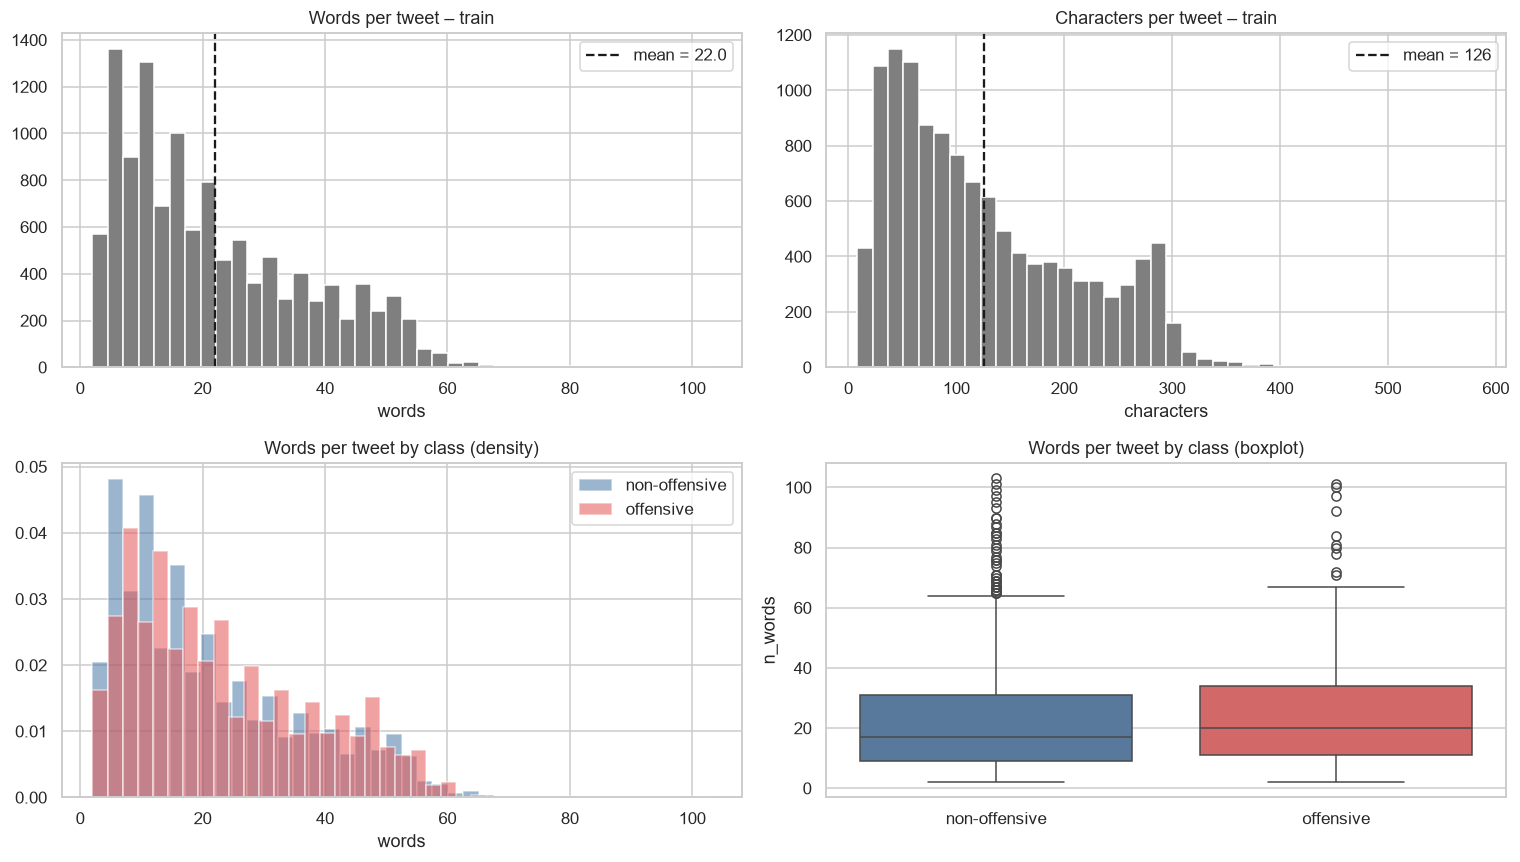

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Top row: global distributions (dashed line = mean)
axes[0, 0].hist(train_len["n_words"], bins=40, color="#7f7f7f", edgecolor="white")
axes[0, 0].axvline(train_len["n_words"].mean(), color="k", ls="--", label=f"mean = {train_len['n_words'].mean():.1f}")
axes[0, 0].set_title("Words per tweet – train"); axes[0, 0].set_xlabel("words"); axes[0, 0].legend()

axes[0, 1].hist(train_len["n_chars"], bins=40, color="#7f7f7f", edgecolor="white")
axes[0, 1].axvline(train_len["n_chars"].mean(), color="k", ls="--", label=f"mean = {train_len['n_chars'].mean():.0f}")
axes[0, 1].set_title("Characters per tweet – train"); axes[0, 1].set_xlabel("characters"); axes[0, 1].legend()

# Bottom-left: densities per class (density=True makes the two classes comparable despite different sizes)
for lab in ["non-offensive", "offensive"]:
    sub = train_len[train_len.label_name == lab]
    axes[1, 0].hist(sub["n_words"], bins=40, alpha=0.55, density=True, color=COLORS[lab], label=lab)
axes[1, 0].set_title("Words per tweet by class (density)"); axes[1, 0].set_xlabel("words"); axes[1, 0].legend()

# Bottom-right: boxplot (median, quartiles, outliers)
sns.boxplot(x="label_name", y="n_words", data=train_len, order=["non-offensive", "offensive"],
            palette=COLORS, ax=axes[1, 1])
axes[1, 1].set_title("Words per tweet by class (boxplot)"); axes[1, 1].set_xlabel("")

savefig(fig, "02_length_histograms.png")

**Results explained.**
- Both histograms (words and characters) are right-skewed, with the mean (dashed line) around 22 words / 126 characters, to the right of the bulk of the tweets.
- The class-density histogram and the boxplot show that the two classes **overlap heavily**: the offensive median is slightly higher (20 vs 17 words) and its quartiles are shifted a few words to the right (11-34 vs 9-31), but the shapes are the same.
- The few very long tweets (about 100 words) are mostly chains of `@user` (see the longest tweets in section 10), not real content.

In [12]:
a = train_len.loc[train_len.label == 0, "n_words"]      # lengths of non-offensive tweets
b = train_len.loc[train_len.label == 1, "n_words"]      # lengths of offensive tweets
# Mann-Whitney U: non-parametric test (no normality assumption) comparing two distributions
stat, p = mannwhitneyu(a, b)
print(f"Median words – non-offensive: {a.median():.0f} | offensive: {b.median():.0f}")
print(f"Mann-Whitney U test: U = {stat:.0f}, p-value = {p:.2e}")
print("-> difference is", "statistically significant" if p < 0.05 else "NOT statistically significant", "(alpha = 0.05)")

Median words – non-offensive: 17 | offensive: 20
Mann-Whitney U test: U = 14464391, p-value = 1.44e-12
-> difference is statistically significant (alpha = 0.05)


**Results explained.**
- Median length: 17 words (non-offensive) vs 20 words (offensive). The Mann-Whitney test (appropriate because length is not normally distributed) gives **U = 14,464,391 and p = 1.4e-12**, so the difference is statistically significant.
- Reading U: with 7,975 × 3,941 = 31.4 million pairs of tweets, U is the number of pairs where the non-offensive tweet is the longer one (ties count one half). U / pairs ≈ **0.46**, against 0.50 if length were unrelated to the class. The effect size is very small (rank-biserial correlation ≈ 0.08).
- The p-value is tiny only because the sample is large. Significant does not mean useful: length alone cannot separate the classes.

**Observations.**
- Tweets are **short** (a few dozen words at most), so the bag-of-words matrix will be **very sparse**.
- Offensive tweets are slightly longer, but the distributions overlap heavily: **length alone is not a useful discriminating feature** and the classifier must rely on the vocabulary.
- No extreme outliers need removal: very short tweets are valid and can still be offensive (e.g. a single insult).

<a id="7"></a>
## 7. Stylistic / surface features
The assignment asks us to justify cleaning choices (negations, stop-words, hashtags, capitals…). To do so we measure how
frequent each of these elements is **per class**: an element that behaves differently between classes carries information
and should perhaps **not** be removed.

In TweetEval, user mentions are already anonymised as `@user` (≈ 92 % of tweets contain one) and, as the check below confirms, **URLs have already been removed** from the text.

In [13]:
# Emoji: unicode ranges of pictographs and symbols
EMOJI_RE = re.compile("[\U0001F300-\U0001FAFF\u2600-\u27BF\U0001F000-\U0001F2FF]")
# Negations: not/no/never..., contractions such as don't, and the generic suffix n't
NEGATION_RE = re.compile(r"\b(?:not|no|never|none|nobody|nothing|neither|nor|can't|cant|won't|don't|dont|doesn't|didn't|isn't|aren't|wasn't|weren't|n't)\b|n't\b", re.I)

# One boolean column per surface element: True if the tweet contains it
feat = pd.DataFrame({
    "mention":      full_df["text"].str.count(r"@\w+") > 0,
    "url":          full_df["text"].str.contains(r"http\S*|www\.", regex=True),
    "hashtag":      full_df["text"].str.contains(r"#\w+", regex=True),
    "emoji":        full_df["text"].apply(lambda t: bool(EMOJI_RE.search(t))),
    "exclamation !":full_df["text"].str.contains("!", regex=False),
    "question ?":   full_df["text"].str.contains("?", regex=False),
    "ALL-CAPS word":full_df["text"].apply(lambda t: any(w.isupper() and len(w) > 2 and w.isalpha() for w in t.split())),
    "elongation (sooo)": full_df["text"].str.contains(r"(\w)\1{2,}", regex=True),     # same letter 3+ times
    "negation":     full_df["text"].str.contains(NEGATION_RE),
    "profanity mask (* or ****)": full_df["text"].str.contains(r"\w\*+\w*|\*{2,}", regex=True),
})
feat["label_name"] = full_df["label_name"]
feat["split"] = full_df["split"]

# Percentage of tweets containing each element, per class (train only)
train_feat = feat[feat.split == "train"]
pct = (train_feat.drop(columns=["split"]).groupby("label_name").mean().T * 100).round(1)
pct["difference (off − non-off)"] = (pct["offensive"] - pct["non-offensive"]).round(1)
pct = pct[["non-offensive", "offensive", "difference (off − non-off)"]]
print("% of tweets containing each element (train):")
display(pct.sort_values("difference (off − non-off)", ascending=False))

% of tweets containing each element (train):


label_name,non-offensive,offensive,difference (off − non-off)
negation,25.7,29.3,3.6
ALL-CAPS word,14.6,16.6,2.0
mention,92.2,94.1,1.9
exclamation !,18.4,19.4,1.0
elongation (sooo),2.1,2.7,0.6
profanity mask (* or ****),0.7,1.0,0.3
url,0.0,0.0,0.0
question ?,15.2,14.3,-0.9
hashtag,15.4,12.6,-2.8
emoji,12.2,9.3,-2.9


**Results explained.** Share of train tweets containing each element, per class:
- Largest gaps, still small: **negation** 25.7 % vs 29.3 % (+3.6), **ALL-CAPS word** 14.6 % vs 16.6 % (+2.0), `!` 18.4 % vs 19.4 % (+1.0). In the other direction: **emoji** (12.2 % vs 9.3 %) and **hashtag** (15.4 % vs 12.6 %) are more frequent in non-offensive tweets.
- `@user` is in about 92-94 % of tweets of both classes, so it does not discriminate. **URLs: 0 %**, confirming that links were already removed from this version of the data.
- No surface feature differs by more than 4 points between the classes: none is a reliable signal on its own.
- Two caveats. (1) The ALL-CAPS test also catches acronyms such as MAGA, CNN or GOP, so it does not measure shouting only. (2) The negation regex only recognises the straight apostrophe (`don't`) and not the curly one (`don’t`), which is common in tweets; this probably underestimates negations. Notebook 02 finds about 31 % of train tweets with a negation after normalising the apostrophe, vs about 27 % here.

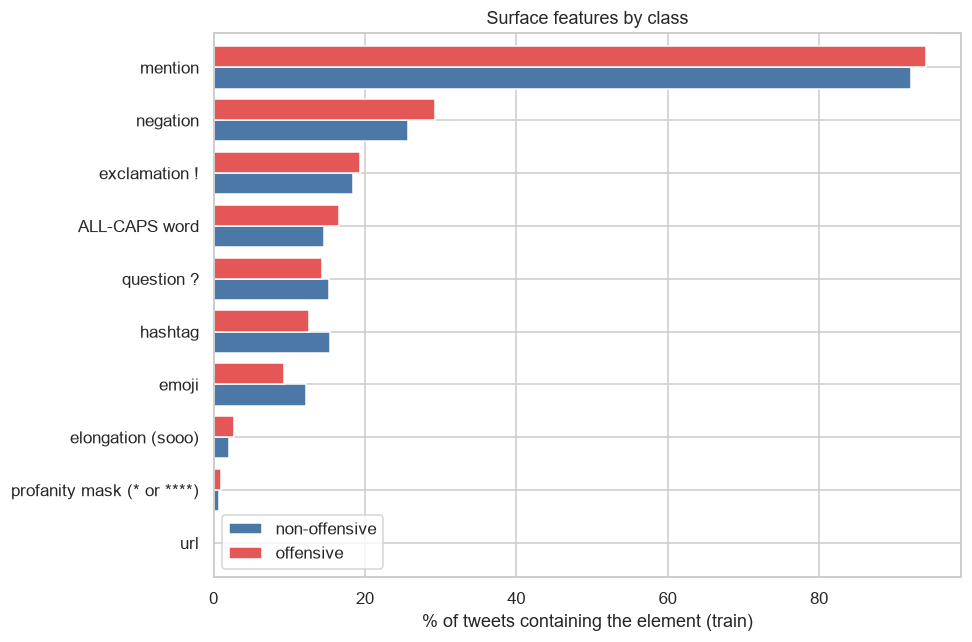

In [14]:
# Horizontal bars: the same table as above, sorted by the offensive-class percentage
plot_df = pct[["non-offensive", "offensive"]].sort_values("offensive")
ax = plot_df.plot(kind="barh", color=PALETTE, figsize=(9, 6), width=0.8)
ax.set_xlabel("% of tweets containing the element (train)")
ax.set_title("Surface features by class")
ax.legend(title="")

# IMPORTANT: ax.get_figure() returns the figure of THIS plot. (Using a stale `fig` variable from an earlier cell
# would save the wrong picture.)
savefig(ax.get_figure(), "03_surface_features.png")

**Results explained.**
- The bars show the same table as above, sorted by the offensive-class percentage: for every feature the red and blue bars have nearly the same length. Visually, the classes are very similar on surface features.
- The figure is saved with `ax.get_figure()`, so `03_surface_features.png` now contains this bar chart (in the previous version it could contain the length histograms).

In [15]:
# Numerical versions of the same features: how MANY mentions / hashtags / ... per tweet
num = pd.DataFrame({
    "n_mentions":   full_df["text"].str.count(r"@\w+"),
    "n_hashtags":   full_df["text"].str.count(r"#\w+"),
    "n_exclam":     full_df["text"].str.count("!"),
    "n_question":   full_df["text"].str.count(r"\?"),
    "n_caps_words": full_df["text"].apply(lambda t: sum(w.isupper() and len(w) > 2 and w.isalpha() for w in t.split())),
    # share of upper-case letters among all letters (max(1, ...) avoids a division by zero)
    "upper_ratio":  full_df["text"].apply(lambda t: sum(c.isupper() for c in t) / max(1, sum(c.isalpha() for c in t))),
})
num["label_name"] = full_df["label_name"]; num["split"] = full_df["split"]
display(num[num.split == "train"].groupby("label_name").mean(numeric_only=True).round(3))

,n_mentions,n_hashtags,n_exclam,n_question,n_caps_words,upper_ratio
label_name,,,,,,
non-offensive,2.752,0.443,0.361,0.221,0.327,0.078
offensive,2.032,0.325,0.438,0.238,0.451,0.077


**Results explained.** Mean counts per tweet (train):
- **Mentions**: 2.75 (non-offensive) vs 2.03 (offensive). Non-offensive tweets are more often part of long reply chains.
- **ALL-CAPS words**: 0.33 vs 0.45 (+38 % in relative terms) and **exclamation marks**: 0.36 vs 0.44 (+21 %): offensive tweets shout a little more.
- Hashtags (0.44 vs 0.33) and question marks (0.22 vs 0.24) differ very little.
- **upper_ratio** is **identical** (0.078 vs 0.077): offensive tweets do not contain more capital letters overall; they contain slightly more fully-capitalised words.
- Counts are small averages (below 3), so these differences are weak signals. Since notebook 02 lowercases the text, the capitalisation cue is lost, which is accepted because it is so weak.

**Observations.** Differences between classes are small for most surface features (≤ 4 points). The largest are **negations** (29 % offensive vs 26 %) and ALL-CAPS words (+2 points); hashtags and emojis are slightly more common in non-offensive tweets. Masked profanity (`f***`) is rare (~1 %). These cues are weak individually, so we keep them (no aggressive cleaning) rather than rely on them.

**Implications for preprocessing.**

| Element | What we look for | Decision to take in notebook 02 |
|---|---|---|
| `@user` mentions | present in ~92–94 % of tweets in both classes → almost no discriminating power | keep as the single placeholder `@user` or drop it |
| URLs (`http`) | 0 % of tweets in this version of the dataset | nothing to remove, but keep the regex for robustness |
| Hashtags | may contain topical words | keep the **word** (remove only `#`) |
| ALL-CAPS, `!` | shouting is a typical aggression cue | lowercasing loses it → consider a feature or keep `!` |
| Negations (`not`, `don't`) | change polarity ("not stupid") | **do not** remove them with the stop-words |
| Profanity masks (`f***`) | offensive even when obfuscated | keep `*` patterns or normalise them |
| Elongations (`sooo`) | emphasis | optional normalisation |

<a id="8"></a>
## 8. Vocabulary analysis
Which words are the most frequent per class, and — more interesting — which words are **the most characteristic** of each class?

A minimal tokenizer (lowercase, alphabetic tokens) is used here for exploration only; the real cleaning is done in notebook 02.

In [16]:
# Stop-words = standard English list + a few Twitter-specific tokens that carry no meaning here
STOP = set(ENGLISH_STOP_WORDS) | {"user", "http", "https", "amp", "rt", "im", "u"}
# A token = a letter followed by letters, apostrophes or asterisks (so "f***" survives)
TOKEN_RE = re.compile(r"[a-z][a-z'\*]+")

def tokenize(text, remove_stop=True):
    toks = TOKEN_RE.findall(text.lower())            # lowercase, then extract tokens
    toks = [t.strip("'") for t in toks]              # remove apostrophes at the edges
    if remove_stop:
        toks = [t for t in toks if t not in STOP and len(t) > 2]   # drop stop-words and very short tokens
    return toks

# One word counter per class (0 / 1), computed on the TRAIN set only
train_only = full_df[full_df.split == "train"]
counter = {lab: Counter() for lab in (0, 1)}
for lab, txt in zip(train_only["label"], train_only["text"]):
    counter[lab].update(tokenize(txt))

print("Distinct tokens (after stop-word removal)  non-offensive:", len(counter[0]), "| offensive:", len(counter[1]))
print("Total tokens                               non-offensive:", sum(counter[0].values()), "| offensive:", sum(counter[1].values()))

all_vocab = set(counter[0]) | set(counter[1])        # union of both vocabularies
print("Vocabulary size (train):", len(all_vocab))
print("Words appearing only once:", sum(1 for w in all_vocab if counter[0][w] + counter[1][w] == 1),
      "  → justifies min_df=2 in the TF-IDF")

Distinct tokens (after stop-word removal)  non-offensive: 13699 | offensive: 9117
Total tokens                               non-offensive: 70245 | offensive: 40326
Vocabulary size (train): 17295
Words appearing only once: 9374   → justifies min_df=2 in the TF-IDF


**Results explained.**
- After stop-word removal: **13,699 distinct tokens** in non-offensive tweets vs **9,117** in offensive ones; **70,245 vs 40,326 tokens in total**. The non-offensive class is larger simply because it has twice as many tweets. Per tweet it is the reverse: about 8.8 content tokens vs 10.2 for offensive tweets, consistent with them being longer.
- Combined vocabulary: **17,295** distinct tokens. Since 13,699 + 9,117 = 22,816, about 5,500 tokens (about one third) occur in **both** classes: the classes share a lot of vocabulary.
- **9,374 tokens (54 %) appear only once** in train: a long tail of rare words and typos. They cannot generalise to new tweets, which justifies `min_df=2` in the TF-IDF vectorizer.

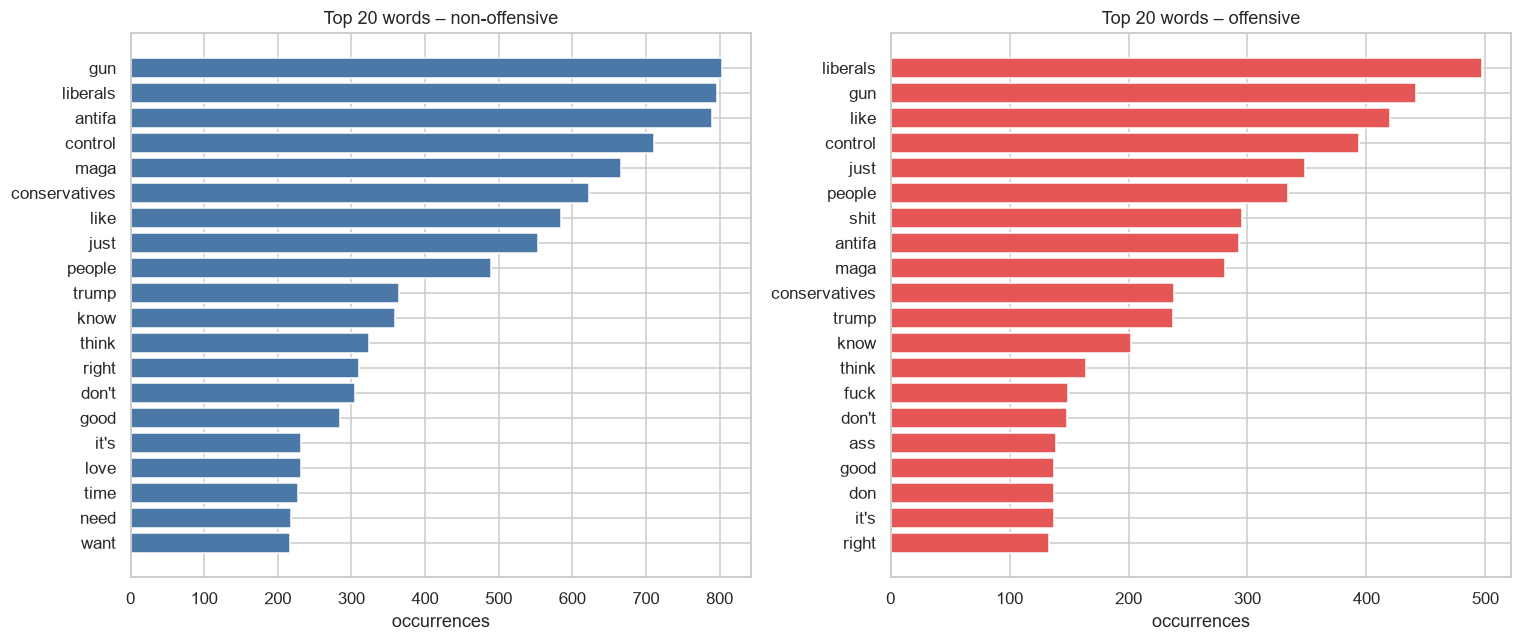

In [17]:
# Top 20 most frequent words of each class
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, lab in zip(axes, (0, 1)):
    name = LABEL_NAMES[lab]
    words, vals = zip(*counter[lab].most_common(20))       # 20 most frequent (word, count) pairs
    ax.barh(words[::-1], vals[::-1], color=COLORS[name])   # reversed so the most frequent is at the top
    ax.set_title(f"Top 20 words – {name}")
    ax.set_xlabel("occurrences")
savefig(fig, "04_top_words_per_class.png")

**Results explained.**
- The most frequent words are almost the same in both classes: `gun`, `control`, `liberals`, `antifa`, `maga`, `conservatives`, `trump`, `like`, `people`. The corpus is clearly **political** (gun control, US politics) in both classes, so topic words do not separate them.
- The only words that appear in the offensive top 20 but not in the non-offensive one are explicit: `shit`, `fuck`, `ass`. In the non-offensive top 20, `love`, `good`, `time`, `need` and `want` are present.
- **Tokenizer artefact**: `don` appears in the offensive list. The token regex does not include the curly apostrophe, so `don’t` is cut into `don` and `t` (and `t` is dropped as too short). This is why notebook 02 converts `’` to `'`.
- Raw frequency is therefore poorly discriminative, which is why the log-odds ratio is used next.

Raw frequency is dominated by words common to both classes. A more informative measure is the **smoothed log-odds ratio**:

$$\text{score}(w) = \log\frac{(c_{off}(w)+1)/(N_{off}+V)}{(c_{non}(w)+1)/(N_{non}+V)}$$

A large positive score → the word is characteristic of the offensive class; a large negative score → of the non-offensive class.
The "+1" (Laplace smoothing) avoids dividing by zero for words absent from one class. Only words with at least 15 occurrences are kept to avoid noise.

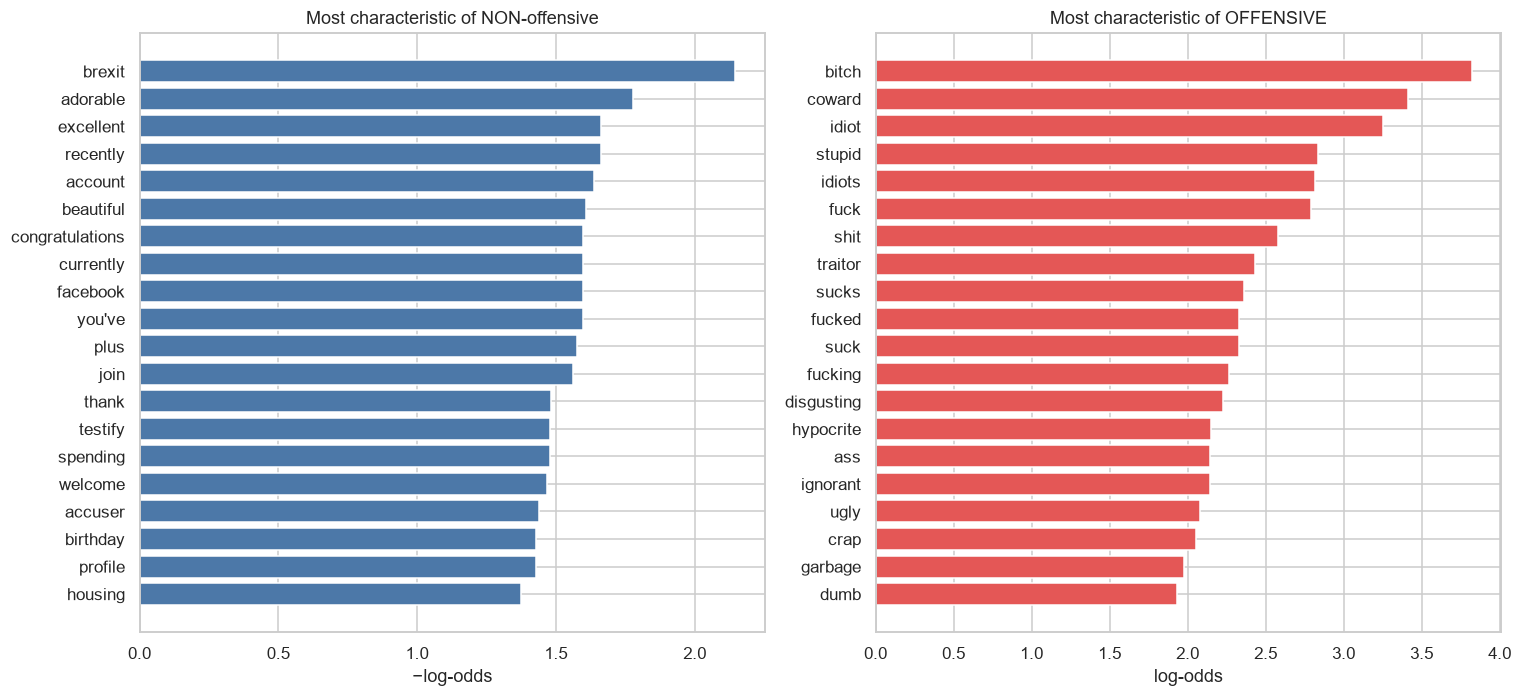

Top discriminative OFFENSIVE words (with counts):


,word,count_non_off,count_off,log_odds
0,bitch,2,89,3.82
1,coward,0,19,3.41
2,idiot,2,50,3.25
3,stupid,8,100,2.84
4,idiots,1,21,2.82
5,fuck,13,149,2.79
6,shit,33,295,2.58
7,traitor,1,14,2.43
8,sucks,5,41,2.36
9,fucked,3,26,2.33


In [18]:
V = len(all_vocab)                                           # vocabulary size (smoothing term)
N0, N1 = sum(counter[0].values()), sum(counter[1].values())  # total tokens per class

rows = []
for w in all_vocab:
    c0, c1 = counter[0][w], counter[1][w]                    # occurrences in non-offensive / offensive
    if c0 + c1 >= 15:                                        # ignore rare words (too noisy)
        score = np.log((c1 + 1) / (N1 + V)) - np.log((c0 + 1) / (N0 + V))
        rows.append((w, c0, c1, score))

lo = pd.DataFrame(rows, columns=["word", "count_non_off", "count_off", "log_odds"]).sort_values("log_odds")
top_off = lo.tail(20).iloc[::-1]     # 20 highest scores = most offensive-specific
top_non = lo.head(20)                # 20 lowest scores = most non-offensive-specific

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
axes[0].barh(top_non["word"][::-1], -top_non["log_odds"][::-1], color=COLORS["non-offensive"])
axes[0].set_title("Most characteristic of NON-offensive"); axes[0].set_xlabel("−log-odds")
axes[1].barh(top_off["word"][::-1], top_off["log_odds"][::-1], color=COLORS["offensive"])
axes[1].set_title("Most characteristic of OFFENSIVE"); axes[1].set_xlabel("log-odds")
savefig(fig, "05_discriminative_words.png")

print("Top discriminative OFFENSIVE words (with counts):")
display(top_off.head(10).round(2).reset_index(drop=True))

**Results explained.**
- **Offensive side**: the highest scores belong to insults and profanity: `bitch` (2 occurrences in non-offensive vs 89 in offensive, score 3.82), `coward` (0 vs 19), `idiot` (2 vs 50), `stupid` (8 vs 100), `fuck`, `shit`, `traitor`, `sucks`. A score of 3.82 means `bitch` is about **e^3.82 ≈ 46 times** more frequent (relative to class size, with smoothing) in offensive tweets.
- Profanity is not a perfect rule: `shit` occurs 33 times in non-offensive tweets, but 295 times in offensive ones (about 90 % of its occurrences).
- **Non-offensive side**: scores are weaker (maximum about 2.1, `brexit`, against 3.8). The vocabulary is polite or positive (`adorable`, `excellent`, `beautiful`, `congratulations`, `thank`, `welcome`, `birthday`) or simply neutral and topical (`brexit`, `facebook`, `account`, `housing`, `spending`, `testify`, `accuser`).
- Interpretation: the offensive class is defined by **the presence of insults**, whereas the non-offensive class is mostly defined by **their absence**. Some non-offensive markers reflect news topics of the collection period and may not generalise.

**Observations.**
- The **offensive** class is characterised by insults and profanity (`bitch`, `idiot`, `stupid`, `fuck`, `shit`, `coward`…), which is why a lexical model (TF-IDF + linear classifier) should work reasonably well.
- The **non-offensive** class is characterised by neutral / positive or topical vocabulary.
- About 54 % of the 17,295 training tokens appear only once → long-tailed vocabulary; `min_df=2` and `max_features` in TF-IDF reduce noise and dimensionality.
- Offensiveness is sometimes **contextual** (sarcasm, implicit insults) and cannot be captured by single words: this limits bag-of-words models and motivates `ngram_range=(1, 2)`.

<a id="9"></a>
## 9. WordClouds per class
Word size is proportional to frequency (stop-words, `@user` and `http` removed).

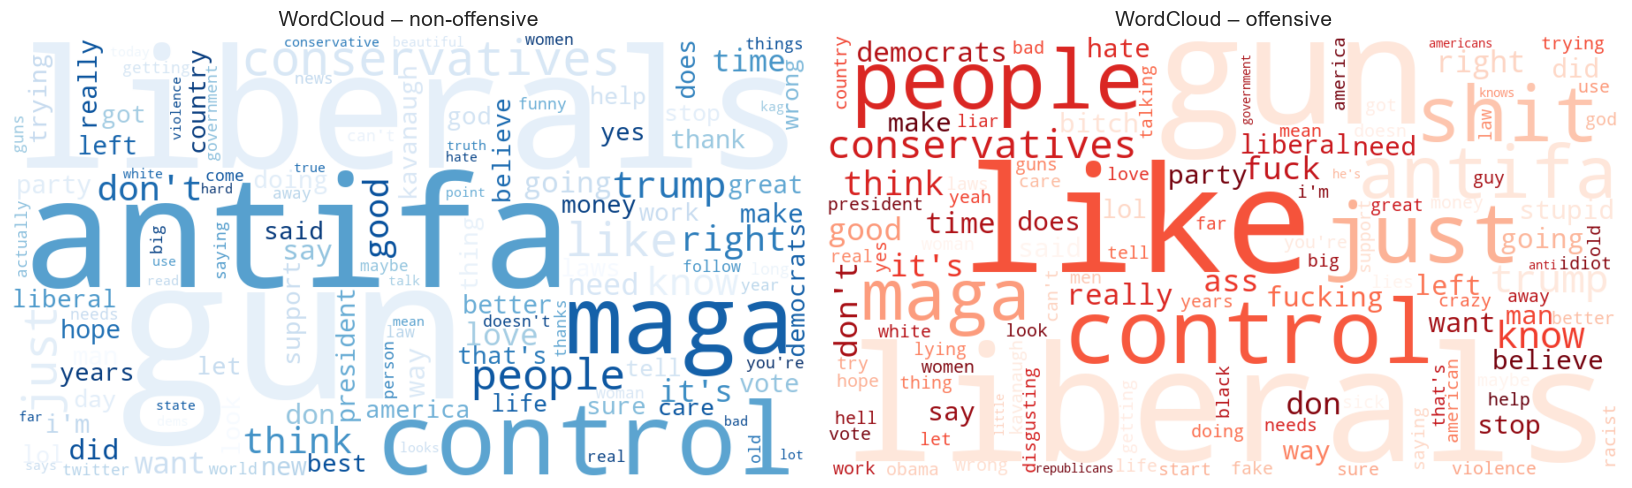

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
cmaps = {0: "Blues", 1: "Reds"}                              # colour maps matching the class colours
for ax, lab in zip(axes, (0, 1)):
    wc = WordCloud(width=900, height=500, background_color="white", colormap=cmaps[lab],
                   max_words=120, random_state=42).generate_from_frequencies(counter[lab])   # fixed seed = reproducible
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off")
    ax.set_title(f"WordCloud – {LABEL_NAMES[lab]}", fontsize=14)
savefig(fig, "06_wordclouds.png")

**Results explained.**
- The clouds are built from the same frequency counts as the bar charts, so the largest words are those of the top-20 charts: political vocabulary (`gun`, `control`, `liberals`, `antifa`, `maga`, `trump`) in both classes.
- The two clouds look alike, which confirms that **what people talk about** does not tell the classes apart. Only a few words (`shit`, `fuck`, `ass`) visibly distinguish the offensive cloud.

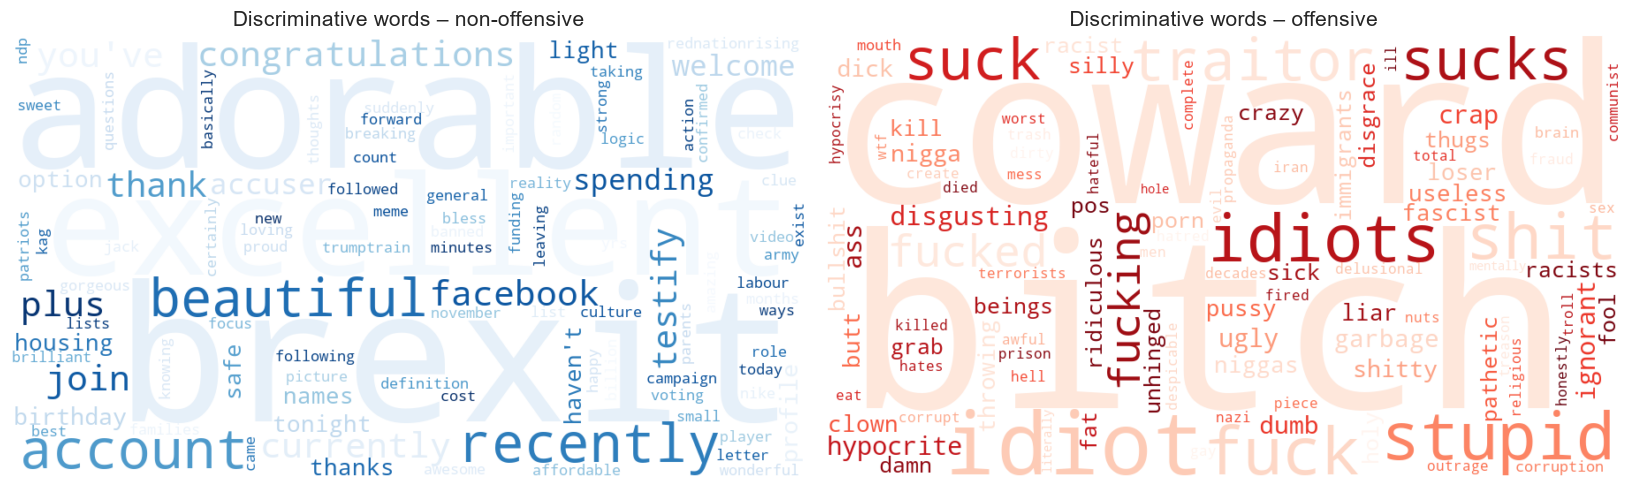

In [20]:
# Second pair of clouds: word size = log-odds score instead of raw frequency
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
pos = lo[lo.log_odds > 0].set_index("word")["log_odds"].to_dict()                       # offensive-specific words
neg = {w: -s for w, s in lo[lo.log_odds < 0].set_index("word")["log_odds"].to_dict().items()}   # sign flipped: sizes must be > 0
for ax, freqs, lab in zip(axes, (neg, pos), (0, 1)):
    wc = WordCloud(width=900, height=500, background_color="white", colormap=cmaps[lab],
                   max_words=100, random_state=42).generate_from_frequencies(freqs)
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off")
    ax.set_title(f"Discriminative words – {LABEL_NAMES[lab]}", fontsize=14)
savefig(fig, "07_wordclouds_discriminative.png")

**Results explained.**
- These clouds use the log-odds score as word size, so each cloud shows what **distinguishes** its class.
- Offensive cloud: insults (`bitch`, `idiot(s)`, `stupid`, `coward`), profanity, and attack words (`hypocrite`, `liar`, `loser`, `useless`, `clown`, `traitor`). It also contains **political and identity words** (`racist(s)`, `fascist`, `immigrants`, `terrorists`, `gay`) and some racial slurs.
- Non-offensive cloud: friendly or neutral words (`adorable`, `excellent`, `beautiful`, `congratulations`, `thank`, `welcome`, `birthday`) and topical words (`brexit`, `facebook`, `account`, `housing`). It is paler than the offensive one because its scores are lower.
- **Bias warning**: identity words such as `immigrants` or `gay` appear because they are used in offensive tweets in this corpus, not because they are offensive themselves. A bag-of-words model may learn to flag neutral tweets that merely mention these groups; this deserves a sentence in the limitations of the report.

**Note.** The first pair of clouds is based on frequency and shows what people talk about; the second pair is based on the log-odds score and highlights what **distinguishes** the classes — it is the more relevant one for classification. *Content warning: the offensive cloud contains vulgar words.*

<a id="10"></a>
## 10. Example tweets
Reading real examples helps to spot difficulties that statistics cannot show (sarcasm, quoted insults, missing context).

In [21]:
pd.set_option("display.max_colwidth", 200)       # show the full tweet in the tables
print("=== 8 random NON-offensive tweets ===")
display(train_df[train_df.label == 0].sample(8, random_state=1)[["text"]].reset_index(drop=True))
print("=== 8 random OFFENSIVE tweets (content warning) ===")
display(train_df[train_df.label == 1].sample(8, random_state=1)[["text"]].reset_index(drop=True))

=== 8 random NON-offensive tweets ===


,text
0,@user What??? She is cute but she doesn't look like me at all
1,@user @user Thank you @user
2,#MAGA Sing like no one is listening Love like you've never been hurt Vote GOP when no one is watching And don't listen to Liberals' dirt
3,Remind me again why exactly there's a lingerie store next to a krav maga dojo
4,@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @use...
5,@user She is!!! 😍
6,@user @user so you say. When you are older you may understand. What anyone believes is quite irrelevant--as you yourself are asserting.
7,@user And god forbid you are already talking to someone or dating they get real mad 😂🤷🏼‍♀️ we like those people over you for a reason sorry bout it 😂


=== 8 random OFFENSIVE tweets (content warning) ===


,text
0,@user So has the Law changed...you just make an allegation now days and your guilty until proven innocent. Liberals are mentally ill!
1,@user @user @user For the love of all things sacred he cannot be voted in. He is well down towrds the bottom of that scummy swamp. The Scales of Justice need to let him drown in his own shit. Make...
2,@user THE DEVIL MADE ME DO IT!!!!! THE UGLY FACE OF LIBERALS! I FEEL SORRY FOR THE INNOCENT HONEST ONES THAT ARE JUST BRAINWASHED!
3,@user State Sponsored Kids Protesting the 2nd Amendment? Youth invasion of D.C. took place as young fascists-in-training were corralled into D.C. to demand that govt strip away the liberties of ...
4,@user Wtf aren’t they treating antifa as terrorism?
5,Really # MAGA VOTE TRUMP 2020
6,@user Cuz liberals are sick of cnn!!!!
7,"@user @user @user This is fun, I asked him for proof and he blocked me. I was about to joke about how he'd go from The Antifa are the real Nazis!"""" to similar alt-shite talking points, boy that su..."


**Results explained** (8 + 8 random tweets, small sample, so only indicative).
- Non-offensive tweets are varied: thanks, compliments, jokes, a tweet that is only a chain of `@user`, and a neutral political hashtag post.
- Offensive tweets are **all political**: attacks on groups ("Liberals are mentally ill!", "the ugly face of liberals", "young fascists-in-training"), some with profanity (`shit`, `shite`, `Wtf`), many without any swear word.
- Some labels are hard to explain from the text alone: "Really # MAGA VOTE TRUMP 2020" or "Cuz liberals are sick of cnn!!!!" are labelled offensive without any insult. The label depends on context (target, tone, the tweet being replied to) that is not in the text.
- Consequences: topic and label are correlated (the model may learn that "political = offensive"), and a bag-of-words model has a ceiling because of implicit and context-dependent offensiveness.

In [22]:
# Extremes: the 5 shortest and the 5 longest tweets of train
tl = full_df[full_df.split == "train"].sort_values("n_words")
print("=== 5 shortest tweets ===")
display(tl.head(5)[["text", "label_name", "n_words"]].reset_index(drop=True))
print("=== 5 longest tweets ===")
display(tl.tail(5)[["text", "label_name", "n_words"]].reset_index(drop=True))

=== 5 shortest tweets ===


,text,label_name,n_words
0,@user well...?,non-offensive,2
1,@user Fool,offensive,2
2,@user Horrible.,offensive,2
3,@user Boycott,non-offensive,2
4,@user Sucks,offensive,2


=== 5 longest tweets ===


,text,label_name,n_words
0,@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @use...,non-offensive,99
1,@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @use...,offensive,100
2,@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @use...,offensive,101
3,@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @use...,non-offensive,101
4,@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @use...,non-offensive,103


**Results explained.**
- **Shortest tweets (2 words)**: the single word after `@user` carries the label: `Fool`, `Horrible.`, `Sucks` are offensive, while `well...?` and `Boycott` are not. A model must handle very short texts correctly; these tweets should not be removed.
- **Longest tweets (99-103 words)**: all start with a very long chain of `@user`, so their length reflects the number of people tagged, not the amount of text written. Their labels are mixed (3 non-offensive, 2 offensive).
- This is why the word-count statistics of section 6 are inflated by mentions, and why the cleaning step (which keeps one `user` token per mention) barely changes tweet length.

<a id="11"></a>
## 11. Conclusions & implications for preprocessing

### Key findings
| # | Finding | Consequence |
|---|---|---|
| 1 | Two clean columns (`text`, `label`), no missing values, official train / val / test splits | no imputation; use the official splits as-is |
| 2 | **Moderate class imbalance** (~1/3 offensive in train, different share in test) | report precision, recall and **F1 of the offensive class**, not only accuracy; consider `class_weight='balanced'` |
| 3 | Tweets are short with a heavy-tailed vocabulary | sparse TF-IDF, `min_df=2`, `max_features≈20 000` |
| 4 | Mentions are anonymised (`@user`, ~93 % of tweets, same rate in both classes); URLs are already absent | no real signal → normalise or drop `@user` |
| 5 | Offensive tweets are strongly marked by profanity / insult words | lexical features (TF-IDF unigrams + bigrams) are appropriate |
| 6 | Negations, `!`, capitals, masked profanity (`f***`) may carry information | **do not** blindly remove all stop-words, keep negations and `*` patterns |
| 7 | Some offensiveness is contextual / sarcastic | expected ceiling for bag-of-words models; BERT-type models are a possible extension |

<a id="12"></a>
## 12. Saving the results
Summary statistics are stored in `results/metrics/01_data_exploration/` so they can be re-used in the report and the final notebook.
Figures were already saved in `results/figures/01_data_exploration/`.

In [23]:
# Summary table: class counts + average length per split
summary = counts.copy()
summary["avg_words"] = full_df.groupby("split")["n_words"].mean().round(2)
summary["avg_chars"] = full_df.groupby("split")["n_chars"].mean().round(2)

EDA_MET_DIR.mkdir(parents=True, exist_ok=True)    # safety: recreate the folder if it was deleted since the setup cell

summary.to_csv(EDA_MET_DIR / "eda_summary.csv")                                                    # sizes, balance, lengths
pct.to_csv(EDA_MET_DIR / "eda_surface_features.csv")                                               # % of tweets per surface element
lo.sort_values("log_odds").to_csv(EDA_MET_DIR / "eda_discriminative_words.csv", index=False)       # log-odds table
quality_df.to_csv(EDA_MET_DIR / "eda_quality_checks.csv")                                          # index kept: it holds the split names

print("Saved metrics:", sorted(p.name for p in EDA_MET_DIR.glob("eda_*.csv")))
print("Saved figures:", sorted(p.name for p in EDA_FIG_DIR.glob("0*.png")))

Saved metrics: ['eda_discriminative_words.csv', 'eda_quality_checks.csv', 'eda_summary.csv', 'eda_surface_features.csv']
Saved figures: ['01_class_distribution.png', '02_length_histograms.png', '03_surface_features.png', '04_top_words_per_class.png', '05_discriminative_words.png', '06_wordclouds.png', '07_wordclouds_discriminative.png']


**Results explained.**
- Four metric files are saved (`eda_summary.csv`, `eda_surface_features.csv`, `eda_discriminative_words.csv`, `eda_quality_checks.csv`) and seven figure files (`01` to `07`) exist in `results/figures/01_data_exploration/`, so everything the report needs from this notebook can be reused without rerunning it.
- Both listings read from the same folders the files were written to (`EDA_MET_DIR`, `EDA_FIG_DIR`), so they always match.
- Hand-over to notebook 02: keep negations, hashtag words and masked profanity; remove URLs, HTML entities and punctuation; do not drop `@user` information blindly.